# 개념 정리

### 5.3. 전이 학습

전이 학습(transfer learning): 큰 데이터셋을 써서 훈련된 모델의 가중치를 가져와 해결할 과제에 맞게 보정해서 사용하는 것. 훈련된 모델은 사전 훈련된 모델(네트워크)라고 함.

#### 5.3.1. 특성 추출 기법

특성 추출(feature extractor): ImageNet 데이터셋으로 사전 훈련된 모델을 가져온 후 마지막에 완전연결층 부분만 새로 만듦.
- 합성곱층: 합성곱층과 풀링층으로 구성
- 데이터 분류기(완전연결층): 추출된 특성을 입력받아 최종적으로 이미지에 대한 클래스를 분류하는 부분

torchvision.transform: 이미지 데이터를 변환하여 모델(네트워크)의 입력으로 사용할 수 있게 변환해줌
- Resize: 이미지의 크기 조정. 합성곱층을 통과하기 위해 조정하는 전처리 과정.
- RandomResizedCrop: 이미지를 랜덤한 크기 및 비율로 자름. 데이터 확장 용도
- RandomHorizontalFlip: 이미지를 랜덤하게 수평으로 뒤집음
- ToTensor: 이미지 데이터를 텐서로 변환

datasets.ImageFolder: 데이터로더가 데이터를 불러올 대상과 방법을 정의
- 첫번째 파라미터: 불러올 경로
- transform: 이미지 데이터에 대한 전처리

DataLoader: 데이터를 불러옴
- 첫 번째 파라미터: 데이터셋
- batch_size: 한 번에 불러올 데이터양을 결정하는 배치 크기
- num_workers: 데이터를 불러올 때 사용할 하위 프로세스 개수
- shuffle: 데이터를 무작위로 섞을지 여부

iter()는 전달된 데이터의 반복자를 꺼내 반환하고, next()는 그 반복자가 다음에 출력해야 할 요소를 반환함.

ResNet18: 50개의 계층으로 구성된 합성곱 신경망. 전이 학습에 사용되도록 사전 훈련된 모델을 제공함. 입력 제약이 매우 크고 충분한 메모리가 없으면 학습 속도가 느릴 수 있는 단점.

param.requires_grad = False : 역전파 중 파라미터들에 대한 변화를 계산할 필요가 없음. 모델의 일부를 고정하고 나머지를 학습하고자 할 때 사용.

- glob: 현재 디렉터리에서 원하는 파일들만 추출하여 가져올 때 사용.
- torch.max: 주어진 텐서 배열의 최댓값이 들어 있는 index 반환
- preds.eq(labels): preds 배열과 labels가 일치하는지 검사

- tensor.clone(): 메모리에 새롭게 할당, 계산 그래프에 계속 상주
- tensor.detach(): 메모리 공유해서 사용, 계산 그래프에 상주X
- tensor.clone().detach(): 메모리에 새롭게 할당, 계산 그래프에 상주X

- clip(): 입력 값이 주어진 범위를 벗어날 때 특정 범위로 제한시킴. image.clip(0, 1)은 image 데이터를 0과 1 사이의 값으로 제한.

#### 5.3.2. 미세 조정 기법

미세 조정(fine_tuning) 기법: 사전 훈련된 모델을 목적에 맞게 재학습시키거나 학습된 가중치의 일부를 재학습.
- 데이터셋이 크고 사전 훈련된 모델과 유사성이 작을 경우: 모델 전체 재학습.
- 데이터셋이 크고 사전 훈련된 모델과 유사성이 클 경우: 합성곱층의 뒷부분과 데이터 분류기 학습.
- 데이터셋이 작고 사전 훈련된 모델과 유사성이 작을 경우: 합성곱층의 일부분과 데이터 분류기 학습. 일부 계층에 미세 조정 기법을 적용해도 효과가 없을 수 있음.
- 데이터셋이 작고 사전 훈련된 모델과 유사성이 클 경우: 데이터 분류기만 학습. 많은 계층에 미세 조정 기법 적용 시 과적합이 발생할 수 있음. 

# 코드 필사

### 5.3. 전이 학습

#### 5.3.1. 특성 추출 기법

In [1]:
# 라이브러리 호출

import os
import time
import copy
import glob
import cv2 # OpenCV 라이브러리
import shutil

import torch
import torchvision # 컴퓨터비전 용도의 패키지
import torchvision.transforms as transforms # 데이터 전처리를 위해 사용되는 패키지
import torchvision.models as models # 다양한 파이토치 네트워크를 사용할 수 있도록 도와주는 패키지
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import DataLoader

import matplotlib.pyplot as plt
import numpy as np

In [2]:
# 이미지 데이터 전처리 방법 정의

data_path = './data/catanddog/train'

transform = transforms.Compose([
    transforms.Resize([256, 256]),
    transforms.RandomResizedCrop(224),
    transforms.RandomHorizontalFlip(),
    transforms.ToTensor()
])
train_dataset = torchvision.datasets.ImageFolder(data_path, transform=transform)
train_loader = torch.utils.data.DataLoader(train_dataset, batch_size=32, num_workers=8, shuffle=True)

print(len(train_dataset))

385


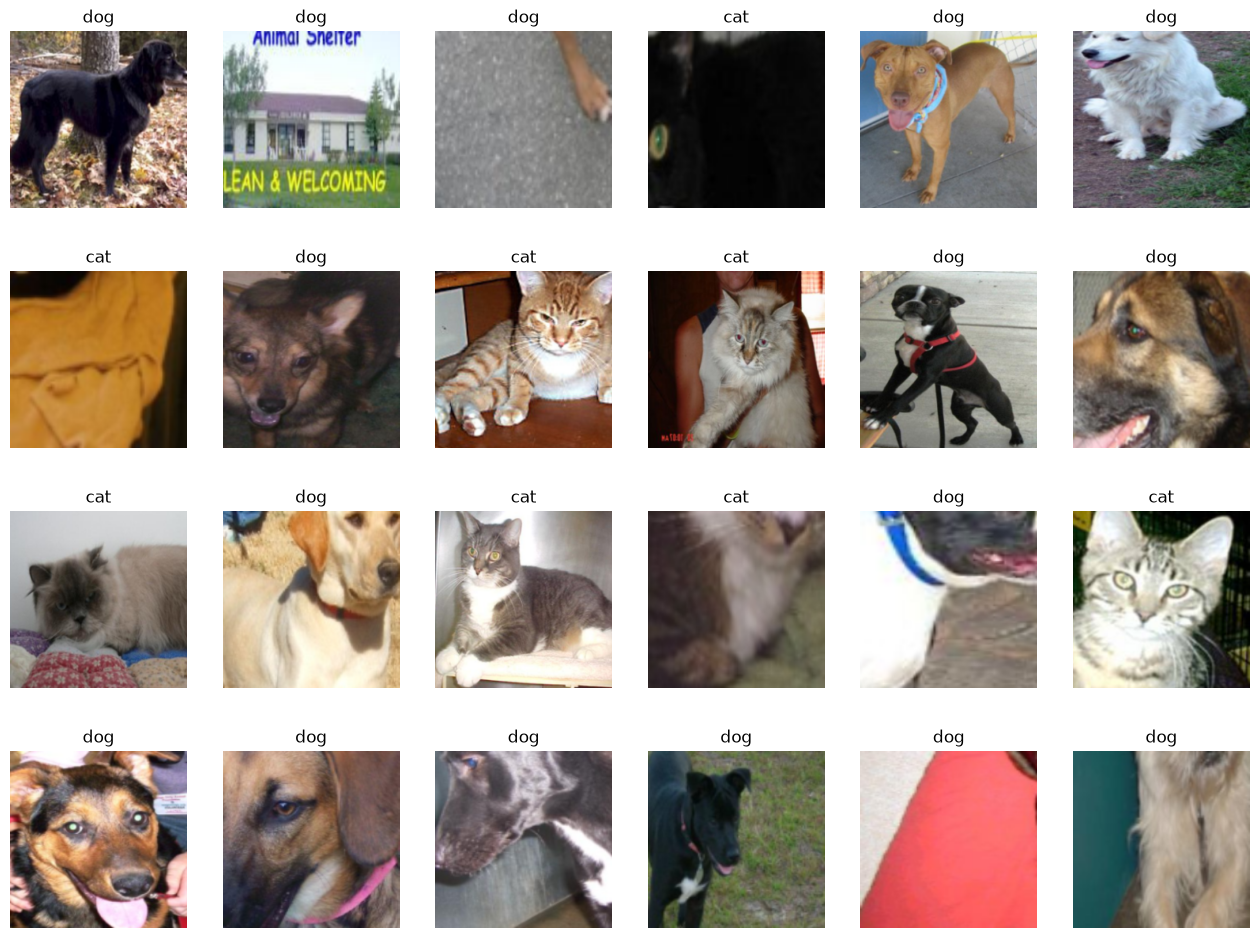

In [3]:
# 학습에 사용될 이미지 출력

samples, labels = next(iter(train_loader))
classes = {0:'cat', 1:'dog'}  # 개와 고양이에 대한 클래스로 구성
fig = plt.figure(figsize=(16, 24))
for i in range(24): # 24개의 이미지 데이터 출력
    a = fig.add_subplot(4, 6, i+1)
    a.set_title(classes[labels[i].item()]) # 레이블 정보(클래스)를 함께 출력
    a.axis('off')
    a.imshow(np.transpose(samples[i].numpy(), (1, 2, 0)))
plt.subplots_adjust(bottom=0.2, top=0.6, hspace=0)

In [4]:
# 사전 훈련된 모델 내려받기
resnet18 = models.resnet18(pretrained=True) # pretrained=True는 사전 학습된 가중치를 사용하겠다는 의미

f:\ESAA\.venv\Lib\site-packages\torchvision\models\_utils.py:207: UserWarning: The parameter 'pretrained' is deprecated since 0.13 and may be removed in the future, please use 'weights' instead.
  warnings.warn(
f:\ESAA\.venv\Lib\site-packages\torchvision\models\_utils.py:222: UserWarning: Arguments other than a weight enum or `None` for 'weights' are deprecated since 0.13 and may be removed in the future. The current behavior is equivalent to passing `weights=ResNet18_Weights.IMAGENET1K_V1`. You can also use `weights=ResNet18_Weights.DEFAULT` to get the most up-to-date weights.
  warnings.warn(msg)


In [5]:
# 사전 훈련된 모델의 파라미터 학습 유무 지정
def set_parameter_requires_grad(model, feature_extracting=True):
    if feature_extracting:
        for param in model.parameters():
            param.requires_grad = False

set_parameter_requires_grad(resnet18)

In [6]:
# ResNet18에 완전연결층 추가
resnet18.fc = nn.Linear(512, 2) # 2는 클래스가 두 개라는 의미

In [7]:
# 모델의 파라미터 값 확인

for name, param in resnet18.named_parameters(): # model.named_parameters()는 모델에 접근하여 파라미터 값들을 가져올 때 사용
    if param.requires_grad:
        print(name, param.data)

fc.weight tensor([[-0.0234, -0.0411,  0.0008,  ...,  0.0350, -0.0313, -0.0036],
        [-0.0031, -0.0031, -0.0399,  ...,  0.0362, -0.0040,  0.0379]])
fc.bias tensor([0.0168, 0.0332])


In [8]:
# 모델 객체 생성 및 손실 함수 정의

model = models.resnet18(pretrained=True) # 모델의 객체 생성

for param in model.parameters(): # 모델의 합성곱층 가중치 고정
    param.requires_grad = False

model.fc = torch.nn.Linear(512, 2)
for param in model.fc.parameters(): # 완전연결층은 학습
    param.requires_grad = True

optimizer = torch.optim.Adam(model.fc.parameters())
cost = torch.nn.CrossEntropyLoss() # 손실함수 정의
print(model)

ResNet(
  (conv1): Conv2d(3, 64, kernel_size=(7, 7), stride=(2, 2), padding=(3, 3), bias=False)
  (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
  (relu): ReLU(inplace=True)
  (maxpool): MaxPool2d(kernel_size=3, stride=2, padding=1, dilation=1, ceil_mode=False)
  (layer1): Sequential(
    (0): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
      (relu): ReLU(inplace=True)
      (conv2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn2): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_stats=True)
    )
    (1): BasicBlock(
      (conv1): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), bias=False)
      (bn1): BatchNorm2d(64, eps=1e-05, momentum=0.1, affine=True, bias=True, track_running_sta

In [9]:
# 모델 학습을 위한 함수 생성

def train_model(model, dataloaders, criterion, optimizer, device, num_epochs=13, is_train=True):
    since = time.time() # 컴퓨터의 현재 시각을 구하는 함수
    acc_history = []
    loss_history = []
    best_acc = 0.0

    for epoch in range(num_epochs):
        print('Epoch {}/{}'.format(epoch, num_epochs-1))
        print('-'*10)

        running_loss = 0.0
        running_corrects = 0

        for inputs, labels in dataloaders:
            inputs = inputs.to(device)
            labels = labels.to(device)

            model.to(device)
            optimizer.zero_grad() # 기울기를 0으로 설정
            outputs = model(inputs) # 순전파 학습
            loss = criterion(outputs, labels)
            _, preds = torch.max(outputs, 1)
            loss.backward() # 역전파 학습
            optimizer.step()

            running_loss += loss.item() * inputs.size(0) # 출력 결과와 레이블의 오차를 계산한 결과를 누적하여 저장
            running_corrects += torch.sum(preds == labels.data) # 출력 결과와 레이블이 동일한지 확인한 결과를 누적하여 저장
            
        epoch_loss = running_loss / len(dataloaders.dataset) # 평균 오차 계산
        epoch_acc = running_corrects.double() / len(dataloaders.dataset) # 평균 정확도 계산

        print('Loss: {:.4f} Acc: {:.4f}'.format(epoch_loss, epoch_acc))

        if epoch_acc > best_acc:
            best_acc = epoch_acc

        acc_history.append(epoch_acc.item())
        loss_history.append(epoch_loss)
        torch.save(model.state_dict(), os.path.join('./data/catanddog/', '{0:0=2d}.pth'.format(epoch)))
        print()

    time_elapsed = time.time() - since # 실행 시간(학습 시간)을 계산
    print('Training complete in {:.0f}m {:.0f}s'.format(time_elapsed // 60, time_elapsed % 60))
    print('Best Acc: {:4f}'.format(best_acc))
    return acc_history, loss_history # 모델의 정확도와 오차를 반환

In [10]:
# 파라미터 학습 결과를 옵티마이저에 전달
params_to_update = []
for name, param in resnet18.named_parameters():
    if param.requires_grad == True:
        params_to_update.append(param) # 파라미터 학습 결과를 저장
        print('\t', name)

optimizer = optim.Adam(params_to_update) # 학습 결과를 옵티마이저에 전달

	 fc.weight
	 fc.bias


In [11]:
# 모델 학습
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
criterion = nn.CrossEntropyLoss() # 손실 함수 지정
train_acc_hist, train_loss_hist = train_model(resnet18, train_loader, criterion, optimizer, device)

Epoch 0/12
----------
Loss: 0.5661 Acc: 0.7065

Epoch 1/12
----------
Loss: 0.3713 Acc: 0.8649

Epoch 2/12
----------
Loss: 0.3379 Acc: 0.8831

Epoch 3/12
----------
Loss: 0.3364 Acc: 0.8364

Epoch 4/12
----------
Loss: 0.2611 Acc: 0.9013

Epoch 5/12
----------
Loss: 0.2411 Acc: 0.9065

Epoch 6/12
----------
Loss: 0.2310 Acc: 0.9065

Epoch 7/12
----------
Loss: 0.2512 Acc: 0.8727

Epoch 8/12
----------
Loss: 0.1912 Acc: 0.9532

Epoch 9/12
----------
Loss: 0.1940 Acc: 0.9351

Epoch 10/12
----------
Loss: 0.1856 Acc: 0.9403

Epoch 11/12
----------
Loss: 0.2058 Acc: 0.9143

Epoch 12/12
----------
Loss: 0.1947 Acc: 0.9221

Training complete in 2m 17s
Best Acc: 0.953247


In [12]:
# 테스트 데이터 호출 및 전처리

test_path = './data/catanddog/test'

transform = transforms.Compose([
    transforms.Resize(224),
    transforms.CenterCrop(224),
    transforms.ToTensor(),
])
test_dataset = torchvision.datasets.ImageFolder(root=test_path, transform=transform)
test_loader = torch.utils.data.DataLoader(test_dataset, batch_size=32, num_workers=1, shuffle=True)

print(len(test_dataset))

98


In [15]:
# 테스트 데이터 평가 함수 생성

def eval_model(model, dataloaders, device):
    since = time.time()
    acc_history = []
    best_acc = 0.0

    saved_models = glob.glob('./data/catanddog/' + '*.pth')
    saved_models.sort() # 불러온 .pth 파일들을 정렬
    print('saved_model', saved_models)

    for model_path in saved_models:
        print('Loading model', model_path)

        model.load_state_dict(torch.load(model_path))
        model.eval()
        model.to(device)
        running_corrects = 0

        for inputs, labels in dataloaders: # 테스트 반복
            inputs = inputs.to(device)
            labels = labels.to(device)

            with torch.no_grad(): # autograd를 사용하지 않겠다는 의미
                outputs = model(inputs) # 데이터를 모델에 적용한 결과를 outputs에 저장

            _, preds = torch.max(outputs.data, 1)
            preds[preds >= 0.5] = 1 # torch.max로 출력된 값이 0.5보다 크면 올바르게 예측
            preds[preds < 0.5] = 0 # torch.max로 출력된 값이 0.5보다 작으면 틀리게 예측
            running_corrects += preds.eq(labels).int().sum()

        epoch_acc = running_corrects.double() / len(dataloaders.dataset) # 테스트 데이터의 정확도 계산
        print('Acc: {:.4f}'.format(epoch_acc))

        if epoch_acc > best_acc:
            best_acc = epoch_acc
            
        acc_history.append(epoch_acc.item())
        print()

    time_elapsed = time.time() - since
    print('Validation complete in {:.0f}m {:.0f}s'.format(time_elapsed // 60, time_elapsed % 60))
    print('Best Acc: {:4f}'.format(best_acc))

    return acc_history # 계산된 정확도 반환

In [16]:
# 테스트 데이터를 평가 함수에 적용

val_acc_hist = eval_model(resnet18, test_loader, device)

saved_model ['./data/catanddog\\00.pth', './data/catanddog\\01.pth', './data/catanddog\\02.pth', './data/catanddog\\03.pth', './data/catanddog\\04.pth', './data/catanddog\\05.pth', './data/catanddog\\06.pth', './data/catanddog\\07.pth', './data/catanddog\\08.pth', './data/catanddog\\09.pth', './data/catanddog\\10.pth', './data/catanddog\\11.pth', './data/catanddog\\12.pth']
Loading model ./data/catanddog\00.pth
Acc: 0.7653

Loading model ./data/catanddog\01.pth
Acc: 0.9184

Loading model ./data/catanddog\02.pth
Acc: 0.9388

Loading model ./data/catanddog\03.pth
Acc: 0.9082

Loading model ./data/catanddog\04.pth
Acc: 0.9184

Loading model ./data/catanddog\05.pth
Acc: 0.9286

Loading model ./data/catanddog\06.pth
Acc: 0.9388

Loading model ./data/catanddog\07.pth
Acc: 0.9388

Loading model ./data/catanddog\08.pth
Acc: 0.9286

Loading model ./data/catanddog\09.pth
Acc: 0.9388

Loading model ./data/catanddog\10.pth
Acc: 0.9388

Loading model ./data/catanddog\11.pth
Acc: 0.9286

Loading mod

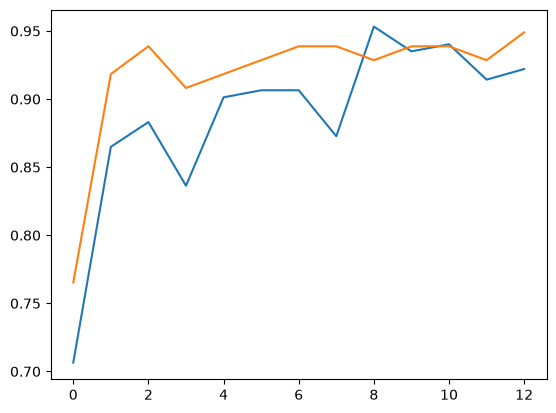

In [17]:
# 훈련과 테스트 데이터의 정확도를 그래프로 확인

plt.plot(train_acc_hist)
plt.plot(val_acc_hist)
plt.show()

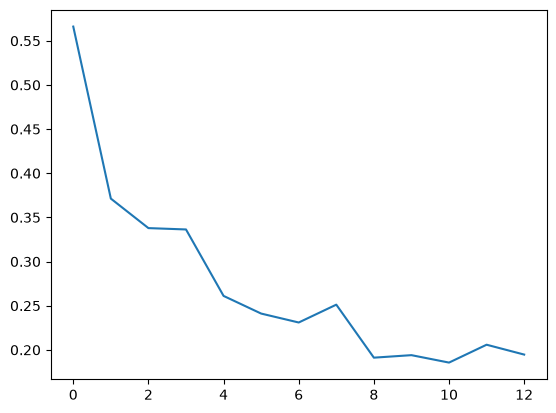

In [18]:
# 훈련 데이터의 오차에 대한 그래프 확인

plt.plot(train_loss_hist)
plt.show()

In [19]:
# 예측 이미지 출력을 위한 전처리 함수

def im_convert(tensor):
    image = tensor.clone().detach().numpy()
    image = image.transpose(1, 2, 0)
    image = image * (np.array((0.5, 0.5, 0.5)) + np.array((0.5, 0.5, 0.5)))
    image = image.clip(0, 1)
    return image

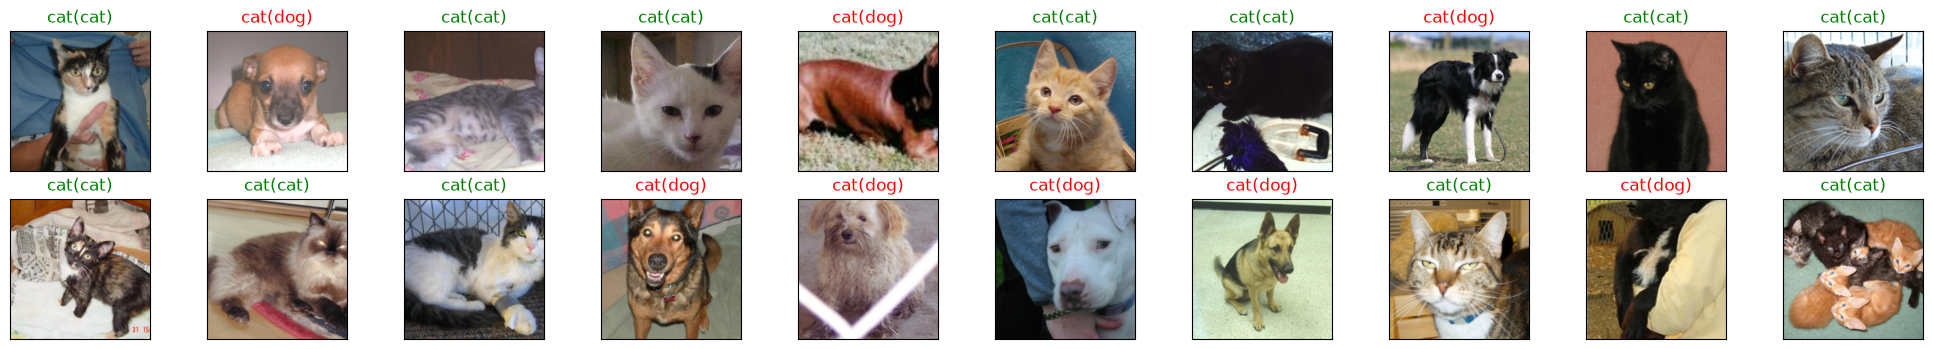

<Figure size 640x480 with 0 Axes>

In [20]:
# 개와 고양이 예측 결과 출력

classes = {0:'cat', 1:'dog'} # 개와 고양이 두 개에 대한 레이블

dataiter = iter(test_loader)
images, labels = next(dataiter)  # 테스트 데이터셋에서 이미지와 레이블을 분리하여 가져옴
output = model(images)
_, preds = torch.max(output, 1)

fig = plt.figure(figsize=(25, 4))
for idx in np.arange(20):
    ax = fig.add_subplot(2, 10, idx+1, xticks=[], yticks=[])
    plt.imshow(im_convert(images[idx])) # 이미지 출력을 위해 위에서 정의한 im_convert 함수를 적용
    a.set_title(classes[labels[i].item()])
    ax.set_title("{}({})".format(str(classes[preds[idx].item()]), str(classes[labels[idx].item()])),
                 color=('green' if preds[idx]==labels[idx] else 'red'))
plt.show()
plt.subplots_adjust(bottom=0.2, top=0.6, hspace=0)